Eccentricity for the particle at time 0 is 0.0038154946818721135
Eccentricity for the particle after 300 planetary orbits is 0.003864651276310275


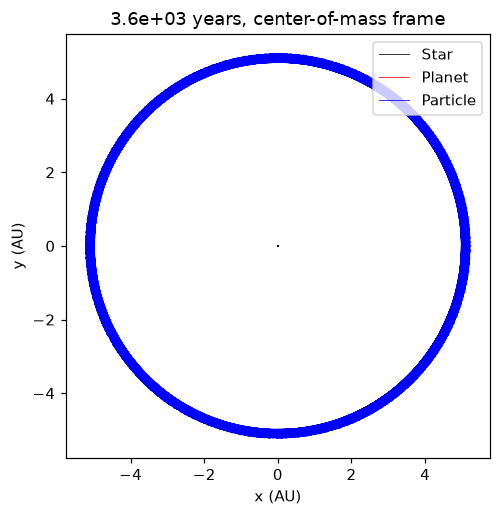

In [67]:
import numpy as np
import astrotools.constants as c
import matplotlib.pyplot as plt
import astrotools.nbody.drag as d
import astrotools.nbody.integrators as n
import astrotools.disk.structure as s

import sys
#print(sys.executable)
import rebound
#print("REBOUND", rebound.__version__)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
sim = rebound.Simulation()
sim.units = ("yr", "AU", "Msun")

mu = 9.54e-4 #planet mass, [Msun], for Jupiter
#mu = 0.03
#mu = 0.05
Msun = (1 - mu) #star mass, [Msun]
a = 5.2 #planet semimajor axis, [AU]
a_m = a * 1.496e+11 #a in meters
epsilon = 10**-3
omega = 31557600 * s.keplerian_omega(a_m) #np.sqrt(4 * np.pi**2 / a**3)
ea = a * epsilon #[AU], epsilon percent of planet semimajor axis
px = (ea / np.sqrt(2)) + (a * (0.5 - mu)) #x coord of particle ea beyond L4
py = (ea / np.sqrt(2)) + (a * np.sqrt(3) / 2) #y coord of particle ea beyond L4

sim.add(m = Msun, x = -1 * mu * a, y = 0, vx = 0, vy = -1 * mu * a * omega, name = 'Sun') #adds sun using velocities and positions
sim.add(m = mu, x = (1 - mu) * a, y = 0, vx = 0, vy = (1 - mu) * a * omega, name = 'Planet') #adds planet, using velocities and positions
sim.add(m = 0, x = px, y = py, vx = py * -omega, vy = px * omega) #adds particle with mass 0 at ea beyond L4, with velocity r x omega

sim.move_to_com() #moves to center-of-mass
sim.integrator = "IAS15"
#plotting the system

n = 300 #number of orbits
o = sim.particles[1].orbit(primary = sim.particles[0]) #planet attributes originally
P = o.P #period of planet
simtime = n * P #time for n planetary orbits, [years]
dt = round(P * 300) #number of sections for times
times = np.linspace(0, simtime, dt) # from 0 to n planetary orbits, dt segments [yr]
xy = np.empty((len(times), 3, 2))
E0 = sim.energy()

p = sim.particles[2].orbit(primary=sim.particles[0]) #tracks particle attributes at t0
print(f'Eccentricity for the particle at time 0 is {p.e}')

for k,t in enumerate(times): #integrates the simulation to time simtime
    sim.integrate(t)
    for i,p in enumerate(sim.particles):
            xy[k,i] = p.x, p.y
relative_energy_error = abs(sim.energy() - E0) / abs(E0) #relative energy error, redundant

p2 = sim.particles[2].orbit(primary=sim.particles[0]) #tracks particle attributes at simtime
print(f'Eccentricity for the particle after 300 planetary orbits is {p2.e}')

fig, ax = plt.subplots(figsize=(5, 5))
for i, (name, c) in enumerate([("Star", "k"), ("Planet", "red"), ("Particle", "blue")]):
    ax.plot(xy[:, i, 0], xy[:, i, 1], color=c, lw=0.5, label=name)
ax.set(aspect="equal", xlabel="x (AU)", ylabel="y (AU)", title=f"{simtime:.1e} years, center-of-mass frame")
ax.legend(loc="upper right")
plt.show()


147.76083217553366 years per libration


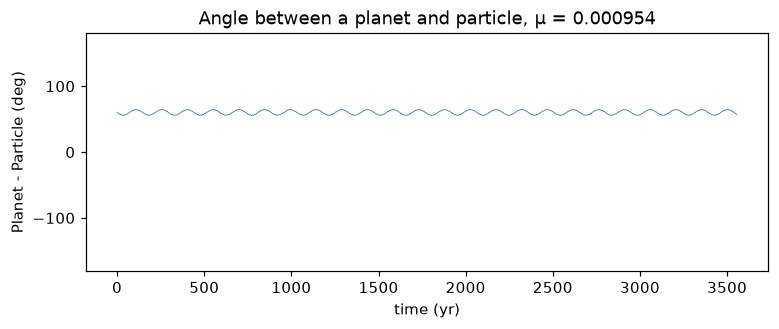

In [68]:
def angle_from_star(xy, i, j):
    """Angle of body j relative to body i as seen from body 0, in degrees."""
    d_i = xy[:, i] - xy[:, 0]
    d_j = xy[:, j] - xy[:, 0]
    ang = np.arctan2(d_j[:, 1], d_j[:, 0]) - np.arctan2(d_i[:, 1], d_i[:, 0])
    return np.degrees((ang + np.pi) % (2 * np.pi) - np.pi)

phi = angle_from_star(xy, 1, 2) #requires two bodies other than the star
librate = P / np.sqrt(27 * mu / 4)
exp_lib = np.linspace(0, librate, dt)

fig1, ax1 = plt.subplots(figsize=(8, 2.8))
ax1.plot(times, phi, lw=.5)
ax1.set(xlabel="time (yr)", ylabel="Planet - Particle (deg)", ylim=(-180, 180))
ax1.set_title(f"Angle between a planet and particle, μ = {mu}")
print(f'{librate} years per libration')

plt.show()